# Quantum Zeno Effect: Freezing Quantum Evolution

### What is the Quantum Zeno Effect?

The **Quantum Zeno Effect** is a phenomenon in quantum mechanics where an evolving quantum system can be "frozen" in its initial state simply by being continuously measured or observed. 

* **The Intuition**: In classical physics, observation doesn't disturb a system. In quantum mechanics, measurement causes **wavefunction collapse**.
  
* **The Mechanism**: If you force a quantum state to collapse back into its initial state ($|0\rangle$) at extremely short time intervals, the system never gets enough time to evolve into the target state ($|1\rangle$).

* **The Analogy**: Much like the old proverb *"a watched pot never boils"*, repeatedly checking a quantum system continuously resets its probability evolution, effectively locking it in place.

## 1. Mathematical Background 

Consider a qubit starting in state $\vert{}0\rangle$. We want to rotate it to state $\vert{}1\rangle$ over a total angle $\theta_{total} = \pi$ using an $R_y$ gate.

If we break this rotation into $N$ equal steps, each small rotation angle is:

$${d}\theta = \frac{\pi}{N}$$

After one small rotation ${d}\theta$, the quantum state becomes:

$$\vert{}\psi_1\rangle = R_y({d}\theta)\vert{}0\rangle = \cos\left(\frac{{d}\theta}{2}\right)\vert{}0\rangle + \sin\left(\frac{{d}\theta}{2}\right)\vert{}1\rangle$$

The probability $P_{survival}^{(1)}$ of measuring the qubit still in $\vert{}0\rangle$ after this single step is:

$$P_{survival}^{(1)} = \vert{}\langle 0 \vert{} \psi_1 \rangle\vert{}^2 = \cos^2\left(\frac{{d}\theta}{2}\right) = \cos^2\left(\frac{\pi}{2N}\right)$$

For small angles (where $N \gg 1$), we use the Taylor expansion $\cos^2(x) \approx 1 - x^2$:

$$P_{survival}^{(1)} \approx 1 - \left(\frac{\pi}{2N}\right)^2 = 1 - \frac{\pi^2}{4N^2}$$

Since we measure at every single step across all $N$ steps, the total survival probability of staying in $\vert{}0\rangle$ is:

$$P_{total}(0) = \left(P_{survival}^{(1)}\right)^N \approx \left(1 - \frac{\pi^2}{4N^2}\right)^N$$

Taking the limit as $N \to \infty$ (continuous measurement):

$$\lim_{N \to \infty} P_{total}(0) = \lim_{N \to \infty} \left(1 - \frac{\pi^2}{4N^2}\right)^N = 1$$

As $N \to \infty$, the probability of decaying to $\vert{}1\rangle$ drops to zero, and the quantum state remains frozen in state $\vert{}0\rangle$.



## 2. Imports

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Qiskit circuit and Aer simulation primitives
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as Sampler

# Setup simulator
backend = AerSimulator()
sampler = Sampler()

## 3. Experiment Function

In [10]:
def simulate_zeno_effect(N: int, total_angle: float = np.pi, shots: int = 2000) -> float:
    """
    Simulates the Quantum Zeno Effect by breaking a rotation into N steps,
    measuring at each step to observe state collapse.
    """
    # 1. Create a circuit with 1 qubit and 1 classical bit
    qc = QuantumCircuit(1, 1)

    # 2. Calculate step angle size: total_angle / N
    delta_theta = total_angle / N

    # 3. Apply rotation and immediate measurement N times
    for _ in range(N):
        qc.ry(delta_theta, 0)  # Rotate by delta_theta
        qc.measure(0, 0)       # Measure immediately (forces state collapse)
        qc.barrier()

    # 4. Run simulation
    job = sampler.run([qc], shots=shots)
    result = job.result()
    counts = result[0].data.c.get_counts()

    # 5. Return probability of staying in |0>
    prob_zero = counts.get('0', 0) / shots
    return prob_zero

## 4. Running the Experiment & Comparing Theory

In [5]:
# Test different measurement counts N
N_values = [1, 2, 3, 5, 10, 20, 50, 100]

empirical_probs = []
theoretical_probs = []

print("Step (N)\t| Empirical P(|0>)\t| Theoretical P(|0>)")
print("-" * 55)

for n in N_values:
    # Run simulation
    prob = simulate_zeno_effect(N=n, total_angle=np.pi, shots=3000)
    empirical_probs.append(prob)
    
    # Calculate exact theoretical probability: [cos(pi / 2N)]^(2N)
    theory = np.cos(np.pi / (2 * n))**(2 * n)
    theoretical_probs.append(theory)
    
    print(f"N = {n:<6}\t| {prob:<18.4f}\t| {theory:.4f}")

Step (N)	| Empirical P(|0>)	| Theoretical P(|0>)
-------------------------------------------------------
N = 1     	| 0.0000            	| 0.0000
N = 2     	| 0.5007            	| 0.2500
N = 3     	| 0.5667            	| 0.4219
N = 5     	| 0.6797            	| 0.6054
N = 10    	| 0.8123            	| 0.7805
N = 20    	| 0.8890            	| 0.8838
N = 50    	| 0.9613            	| 0.9518
N = 100   	| 0.9773            	| 0.9756


## 5. Plotting The Resullts

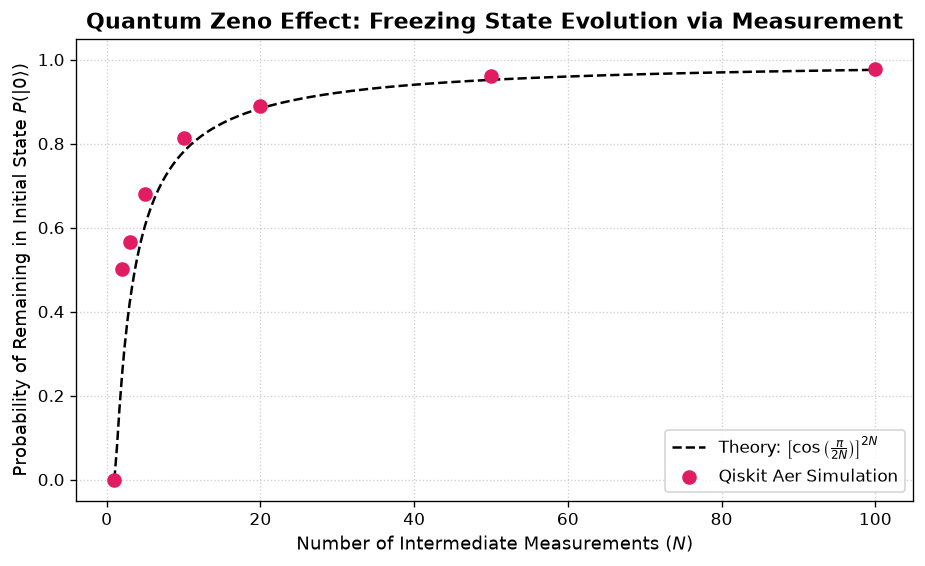

In [6]:
# Prepare dense values for the smooth theoretical curve
N_dense = np.linspace(1, 100, 300)
theory_dense = np.cos(np.pi / (2 * N_dense)) ** (2 * N_dense)

# Plotting the results
plt.figure(figsize=(9, 5), dpi=120)

# Use 'r' in front of the string to make it a raw string (prevents \r from acting as a newline)
plt.plot(N_dense, theory_dense, 'k--', label=r'Theory: $\left[\cos\left(\frac{\pi}{2N}\right)\right]^{2N}$')
plt.scatter(N_values, empirical_probs, color='#E21C63', s=60, zorder=5, label='Qiskit Aer Simulation')

plt.title('Quantum Zeno Effect: Freezing State Evolution via Measurement', fontsize=13, fontweight='bold')
plt.xlabel('Number of Intermediate Measurements ($N$)', fontsize=11)
plt.ylabel(r'Probability of Remaining in Initial State $P(|0\rangle)$', fontsize=11)

plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.show()

## Conclusion

This project successfully demonstrates the **Quantum Zeno Effect** using Qiskit, connecting fundamental quantum mechanics theory with practical quantum circuit simulation.

Key takeaways from the project include:

* **Theoretical Grounding**: Utilizing rotation gates ($R_y$) and continuous intermediate measurements to mathematically prove how high measurement frequencies freeze state evolution.
  
* **Empirical Validation**: Simulating the experiment across varying measurement counts ($N$) via Qiskit Aer to show that as $N \to \infty$, the survival probability $P(\vert{}0\rangle)$ converges to $1.0$.

* **Visual Verification**: Comparing empirical simulation data against theoretical cosine-expansion curves using `matplotlib`.